In [7]:
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib as mpl
import pandas as pd

data = pd.read_csv("./data/coating.ras", delimiter=" ")
plt.rcParams['text.usetex'] = False # Enables LaTeX
plt.rcParams['figure.dpi'] = 300 # Generates HD Graphs


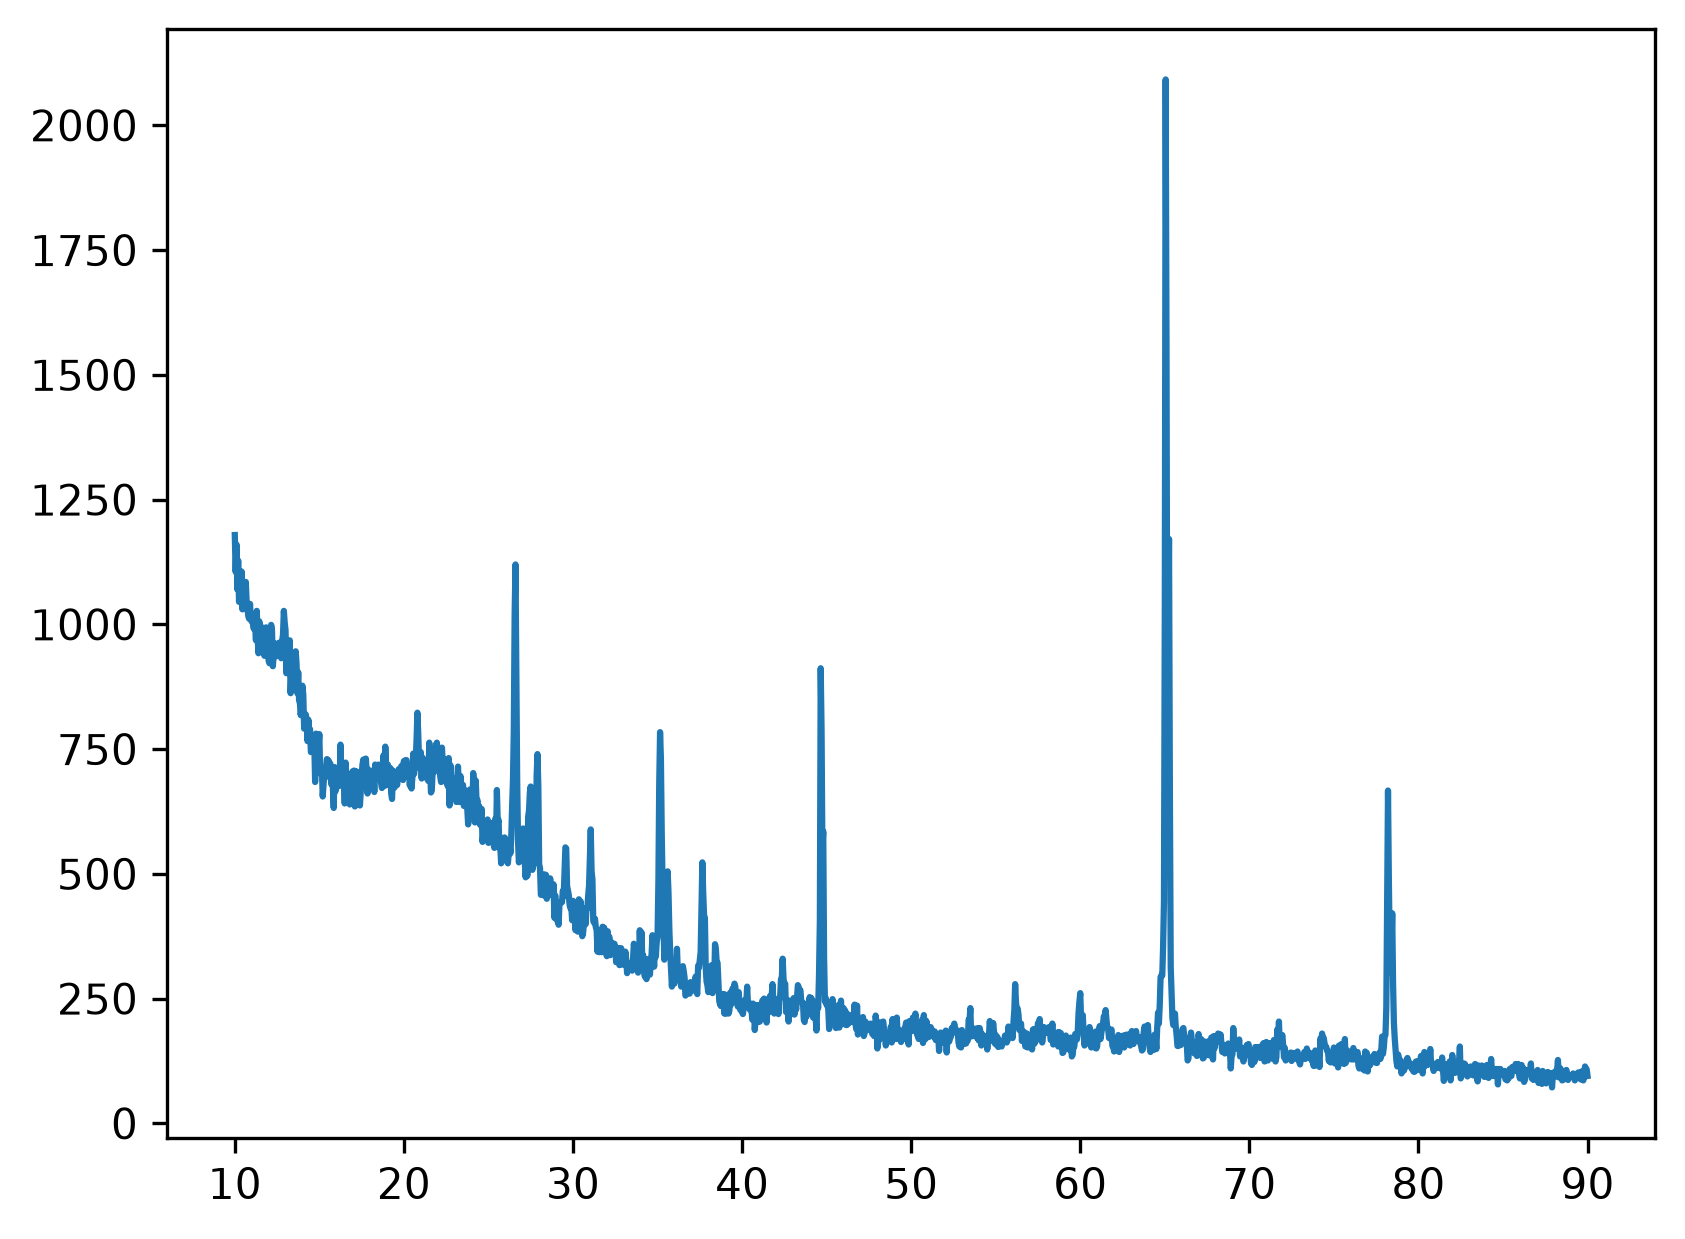

In [2]:
plt.plot(data["lambda"], data['intensity'])

In [16]:
def plot_xrd_against_mp(
    exp_file_path: str,
    api_key: str,
    chemsys: list[str] = ["Al", "Fe", "Si-O", "Al-Fe"],
    two_theta_range: tuple[float, float] = (10, 90),
    wavelength: str = "CuKa",
    energy_above_hull_cutoff: float = 0.01,
    save_cifs_dir: str = "cif_files"
):
    """
    Pulls structures from Materials Project, saves CIFs, simulates XRD patterns,
    and plots them against experimental XRD data.
    
    Parameters:
    - exp_file_path: Path to experimental 2-column (2theta, intensity) data file (.xy, .csv, .txt).
    - api_key: Your Materials Project API key (from next-gen.materialsproject.org).
    - chemsys: List of chemical systems to query (e.g., ["Al", "Fe", "Al-Fe", "Si-O"]).
    - two_theta_range: Tuple of (min_2theta, max_2theta).
    - wavelength: X-ray radiation source (default 'CuKa' = 1.54184 Å).
    - energy_above_hull_cutoff: Max energy above hull (eV/atom) to filter out unstable polymorphs.
    - save_cifs_dir: Directory to save the downloaded CIF files.
    """
    
    # 1. Load Experimental Data
    # Assumes a 2-column file (2theta, intensity). Adjust 'sep' and 'skiprows' for your specific instrument output.
    try:
        exp_data = pd.read_csv(exp_file_path, sep=' ', engine='python', comment='#', header=None)
        # Drop any non-numeric header rows if present
        exp_data = exp_data.apply(pd.to_numeric, errors='coerce').dropna()
        exp_2theta = exp_data.iloc[:, 0].values
        exp_intensity = exp_data.iloc[:, 1].values
    except Exception as e:
        raise ValueError(f"Error reading experimental file: {e}. Check delimiter and header lines.")

    # Filter experimental data to the specified 2-theta range and normalize to 100
    mask = (exp_2theta >= two_theta_range[0]) & (exp_2theta <= two_theta_range[1])
    exp_2theta = exp_2theta[mask]
    exp_intensity = exp_intensity[mask]
    exp_intensity_norm = (exp_intensity / np.max(exp_intensity)) * 100

    # 2. Query Materials Project and Save CIFs
    os.makedirs(save_cifs_dir, exist_ok=True)
    structures = {}
    
    with MPRester(api_key) as mpr:
        for sys in chemsys:
            docs = mpr.materials.summary.search(
                chemsys=sys,
                energy_above_hull=(0, energy_above_hull_cutoff),
                theoretical = False,
                fields=["material_id", "formula_pretty", "structure", "energy_above_hull"]
            )
            for doc in docs:
                label = f"{doc.formula_pretty} ({doc.material_id})"
                structures[label] = doc.structure
                
                # Save CIF file locally
                cif_path = os.path.join(save_cifs_dir, f"{doc.formula_pretty}_{doc.material_id}.cif")
                doc.structure.to(filename=cif_path)
                
    print(f"Downloaded {len(structures)} stable phases and saved CIFs to '{save_cifs_dir}/'.")

    # 3. Initialize XRD Calculator and Plot Setup
    calculator = XRDCalculator(wavelength=wavelength)
    
    num_refs = len(structures)
    fig, axes = plt.subplots(
        nrows=num_refs + 1, 
        ncols=1, 
        figsize=(10, 2.5 + 1.2 * num_refs), 
        sharex=True,
        gridspec_kw={'height_ratios': [3] + [1] * num_refs}
    )
    
    if num_refs == 0:
        axes = [axes]

    # 4. Plot Experimental Spectrum (Top Panel)
    ax_exp = axes[0]
    ax_exp.plot(exp_2theta, exp_intensity_norm, color='black', lw=1.2, label='Experimental Sample (Al-Fe + SiO2)')
    ax_exp.set_ylabel("Normalized Intensity (a.u.)")
    ax_exp.set_title("Experimental XRD vs. Materials Project Reference Phases")
    ax_exp.legend(loc="upper right")
    ax_exp.grid(axis='x', linestyle='--', alpha=0.5)

    # 5. Calculate and Plot Simulated Reference Stick Patterns
    cmap = mpl.colormaps.get_cmap('tab10')
    
    for idx, (label, struct) in enumerate(structures.items()):
        ax_ref = axes[idx + 1]
        pattern = calculator.get_pattern(struct, two_theta_range=two_theta_range)
        
        # Plot sticks for reference peaks
        ax_ref.vlines(pattern.x, 0, pattern.y, color=cmap(idx), lw=1.5, label=label)
        
        # Also plot vertical guide lines up into the experimental plot for top 3 strongest peaks
        top_peaks_idx = np.argsort(pattern.y)[-3:]
        for peak_i in top_peaks_idx:
            ax_exp.axvline(pattern.x[peak_i], color=cmap(idx), linestyle=':', alpha=0.4, lw=1)

        ax_ref.set_ylim(0, 110)
        ax_ref.set_yticks([])
        ax_ref.legend(loc="upper right", frameon=False, fontsize=9)
        ax_ref.grid(axis='x', linestyle='--', alpha=0.5)

    axes[-1].set_xlabel(r"$2\theta$ (degrees)")
    axes[-1].set_xlim(two_theta_range)
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.08)
    plt.show()

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/2 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/16 [00:00<?, ?it/s]

Downloaded 20 stable phases and saved CIFs to 'cif_files/'.


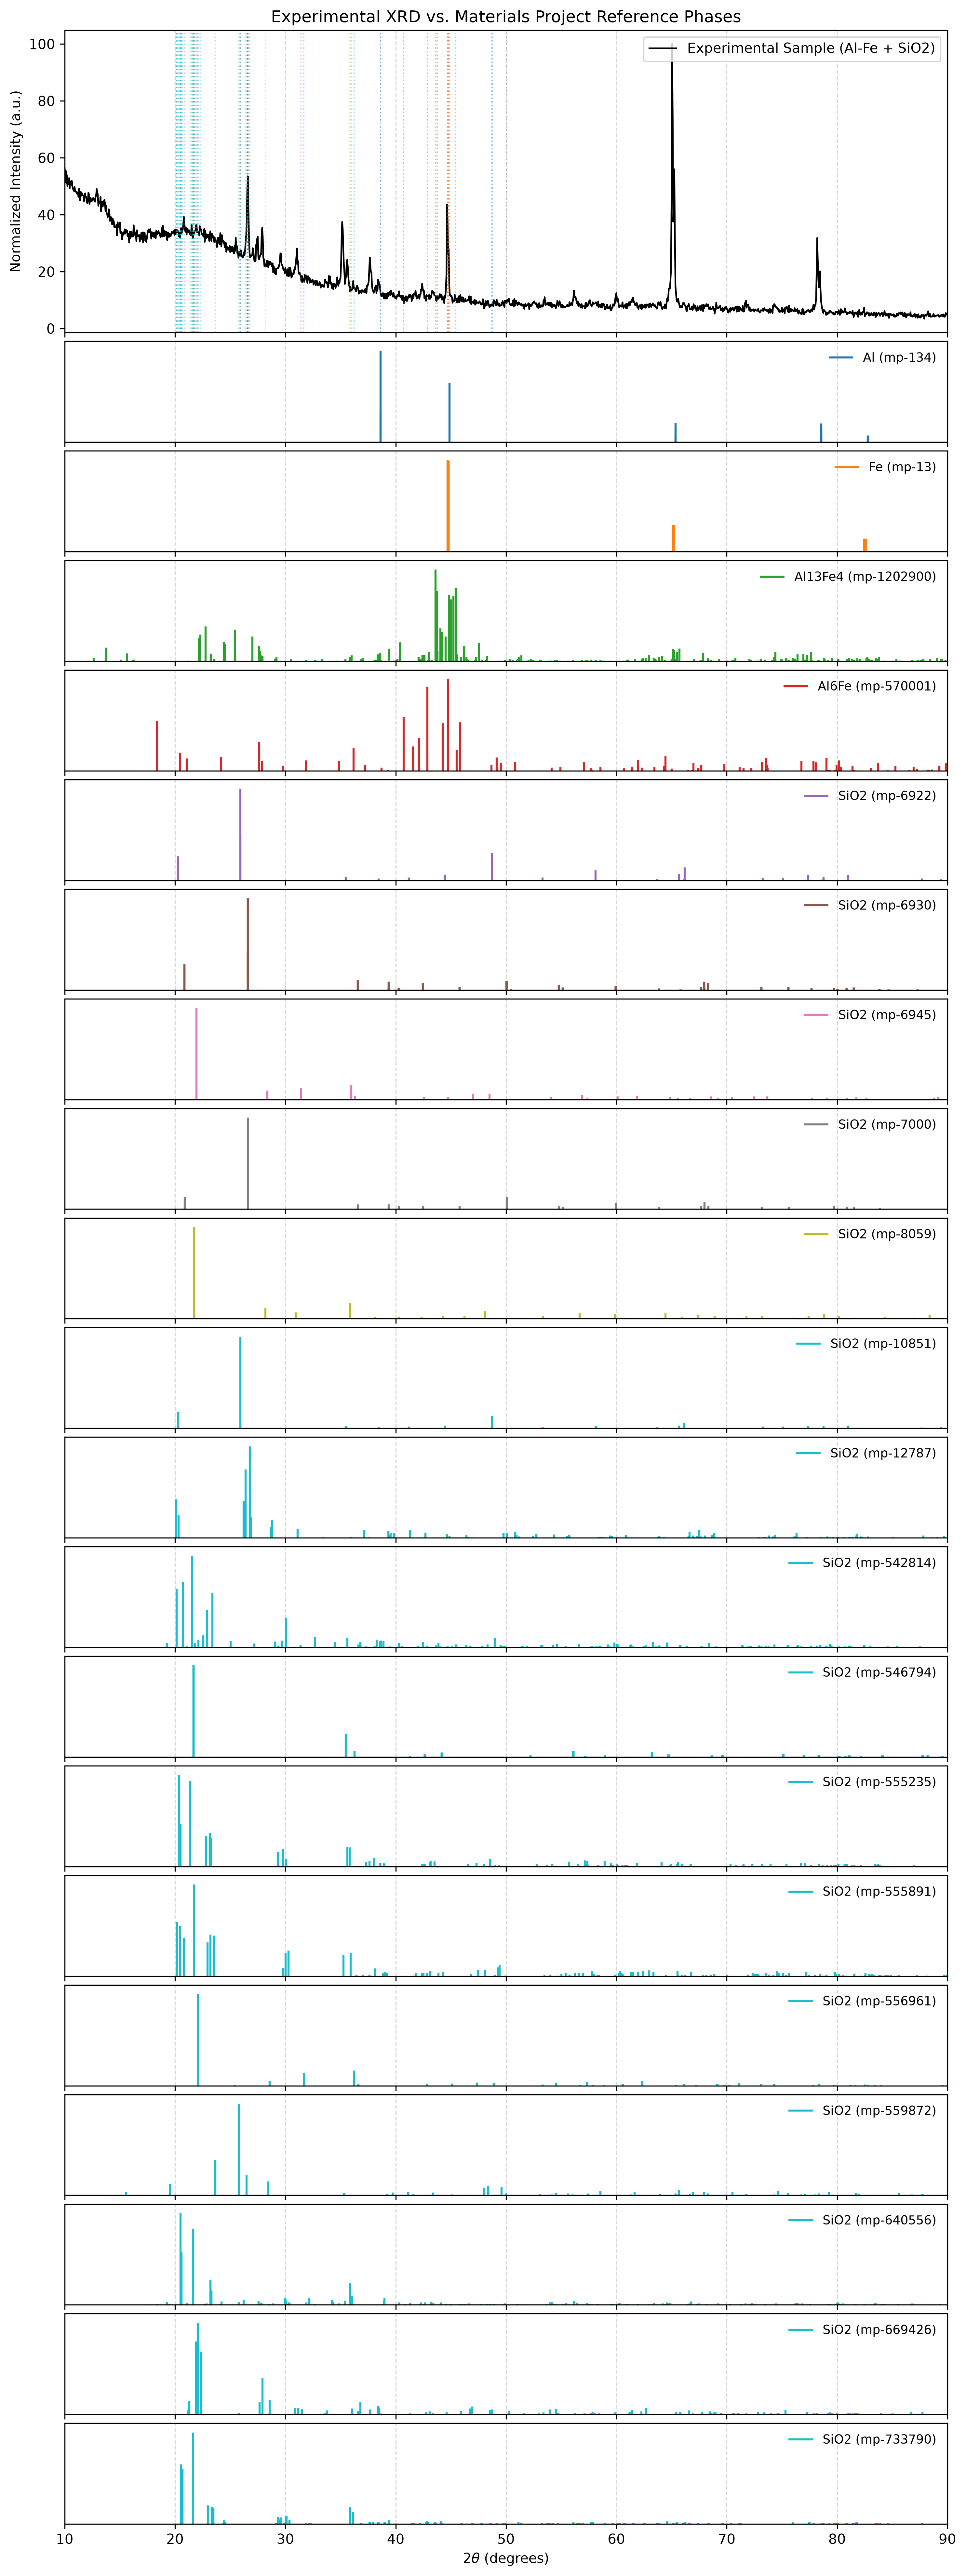

In [17]:
import os
from mp_api.client import MPRester
from pymatgen.analysis.diffraction.xrd import XRDCalculator
MY_MP_API_KEY = os.getenv("API_KEY")
plot_xrd_against_mp(exp_file_path='./data/coating.ras', api_key=MY_MP_API_KEY, chemsys=['Al', 'Fe', 'Al-Fe', 'Si-O'], energy_above_hull_cutoff=0.01)

In [15]:
with MPRester(MY_MP_API_KEY) as mpr:
    list_of_available_fields = mpr.materials.summary.available_fields
print(list_of_available_fields)

['phonon_IDs', 'theoretical', 'database_IDs', 'possible_species', 'weighted_surface_energy_EV_PER_ANG2', 'weighted_surface_energy', 'weighted_work_function', 'surface_anisotropy', 'shape_factor', 'has_reconstructed', 'e_ij_max', 'e_total', 'e_ionic', 'e_electronic', 'n', 'bulk_modulus', 'shear_modulus', 'universal_anisotropy', 'homogeneous_poisson', 'is_magnetic', 'ordering', 'total_magnetization', 'total_magnetization_normalized_vol', 'total_magnetization_normalized_formula_units', 'num_magnetic_sites', 'num_unique_magnetic_sites', 'types_of_magnetic_species', 'dos', 'dos_energy_up', 'dos_energy_down', 'bandstructure', 'band_gap', 'cbm', 'vbm', 'efermi', 'is_gap_direct', 'is_metal', 'grain_boundaries', 'xas', 'uncorrected_energy_per_atom', 'energy_per_atom', 'formation_energy_per_atom', 'energy_above_hull', 'is_stable', 'equilibrium_reaction_energy_per_atom', 'decomposes_to', 'builder_meta', 'nsites', 'elements', 'nelements', 'composition', 'composition_reduced', 'formula_pretty', 'fo